In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
from HSA_Cam_A_007 import (
    Chem,
    bmodel,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    model_inference,
    theta_true,
    y0_true,
    sigma,
)
import xarray

import os

os.environ["MKL_THREADING_LAYER"] = "GNU"
import pytensor

pytensor.config.blas__ldflags = "-lmkl_rt"

In [2]:
plt.style.use("ICIWstyle")

## The base model

In [3]:
times = np.linspace(0, 1 * 60 * 60, 100)

y_true = xarray.DataArray(
    np.zeros((6, len(times), 5)),
    dims=["temperature", "time", "state"],
    coords={
        "temperature": [250, 280, 300, 320, 350, 400],
        "time": times,
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl", "c_Dl"],
    },
)
# display(y_true.coords["temperature"])

for i, T in enumerate(y_true.coords["temperature"]):
    theta = (
        theta_true[0],
        T,
        theta_true[2],
        theta_true[3],
        theta_true[4],
        theta_true[5],
        theta_true[6],
    )
    y_true[i, :, :] = odeint(
        Chem.reaction, t=times, y0=y0_true, args=(np.array(theta),)
    )
y_true[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)

# Add noise
t_obs = times[::10]
y_obs = np.random.normal(y_true[4, :, :], sigma)[::10, :]  # downsample and add noise

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


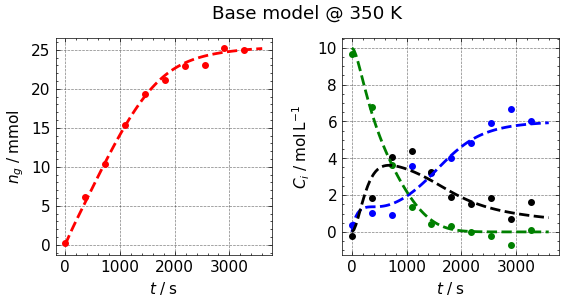

In [4]:
## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_true_data(axs, times, y_true[4, :, :])
plot_observed_data(axs, t_obs, y_obs)
plt.suptitle("Base model @ 350 K")
plt.show()

## Sample the prior distribution

In [5]:
model = bmodel(t_obs, 350, y_obs)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
Sampling: [A01, A02, EA1, EA2, LH2, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


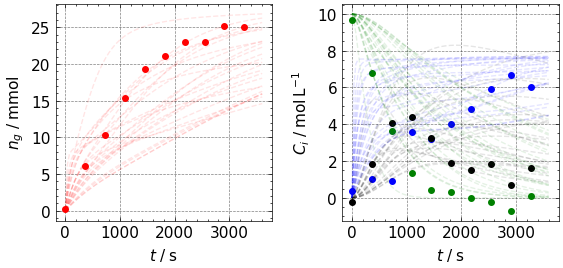

In [6]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
plot_observed_data(axs, t_obs, y_obs)
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

## Sample the posterior given the first profile at 350 K

In [8]:
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_007_posterior.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_007_posterior.nc")

Multiprocess sampling (4 chains in 4 jobs)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]
Could not pickle model, sampling singlethreaded.
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]


Output()

c:\Users\hanne\Documents\Python Scripts\BIBO\HSA_Cam_A_006_lib.py:49: ODEintWarning: Excess work done on this call 
(perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(func=Chem.reaction, y0=y0, t=t, args=(theta,))

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 93 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


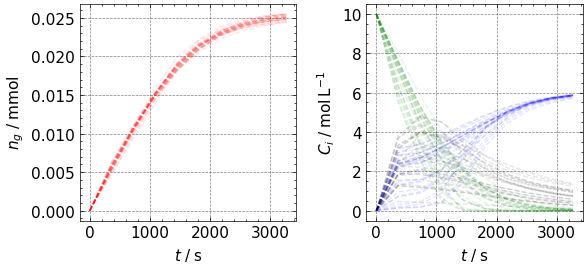

In [8]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)
# display(post_data)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs,
        post_data.values[:, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


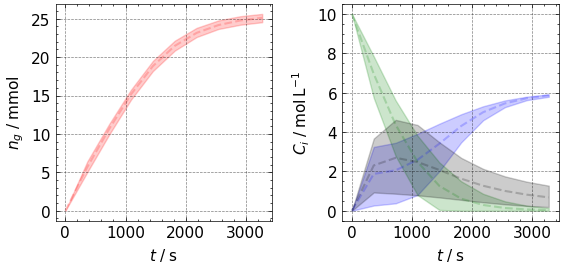

In [9]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
).copy()
# display(post_data)

post_data[:, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

# plot_true_data(axs, times, y_true, lw=2)

plot_true_data(
    axs,
    t_obs,
    post_data.values.mean(axis=2),
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 0],
    np.percentile(post_data.values, 95, axis=2)[:, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 1],
    np.percentile(post_data.values, 95, axis=2)[:, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 2],
    np.percentile(post_data.values, 95, axis=2)[:, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 3],
    np.percentile(post_data.values, 95, axis=2)[:, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

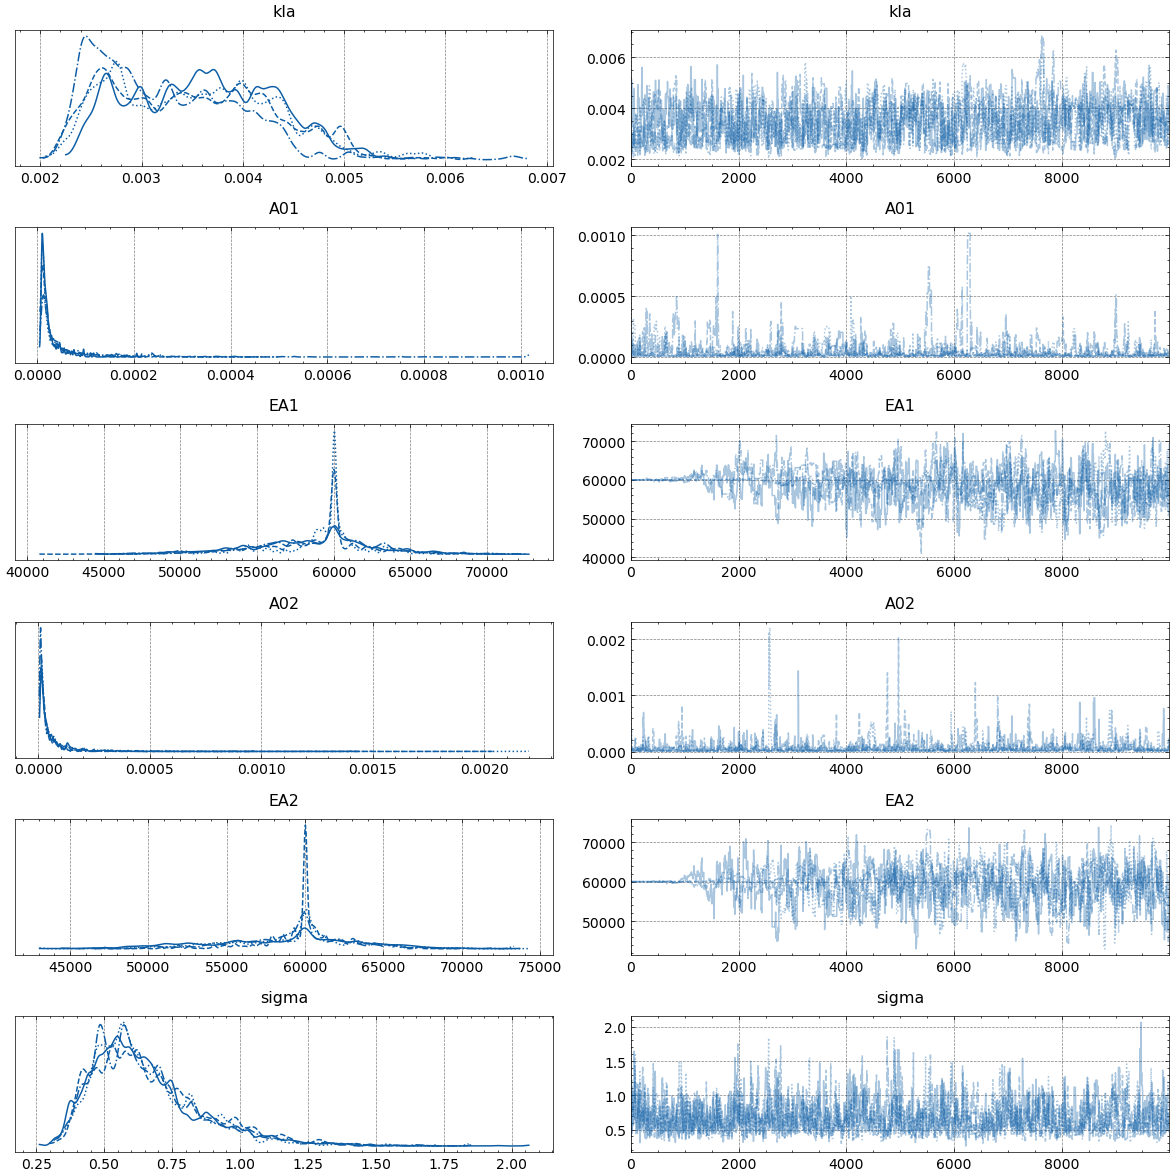

In [10]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


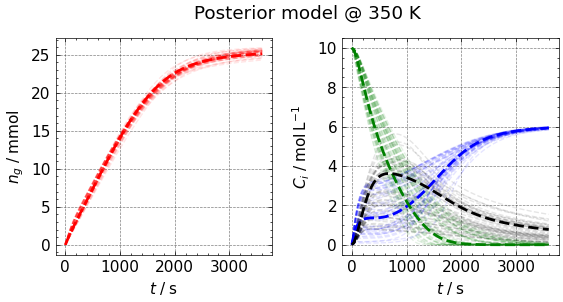

In [11]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

Text(0.5, 0.98, 'Posterior model @ 300 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


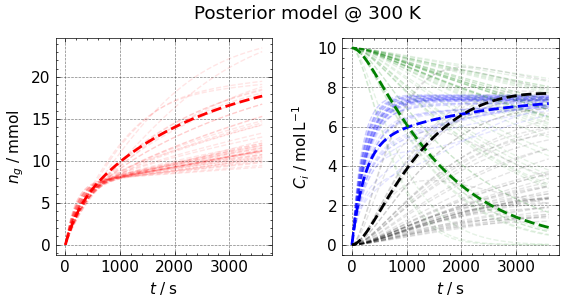

In [12]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 300),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[2, :, :])
plt.suptitle("Posterior model @ 300 K")

### How does the posterior behave given extrapolation?

In [13]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


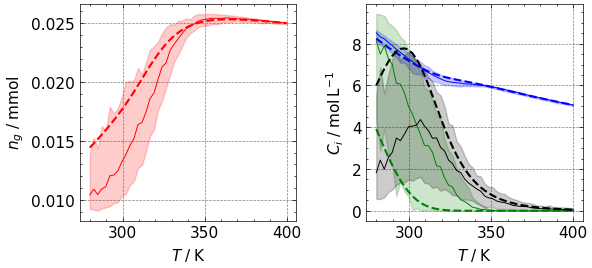

In [14]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

### Calculate the estimated kl divergence as an acquisition function

In [15]:
def idata_to_param_dict(
    idata: az.InferenceData,
    n_samples: int,
) -> dict[str, np.ndarray]:
    """Return dict varname -> (n_samples,) flattened array from arviz InferenceData.posterior."""
    posterior = az.extract(
        idata,
        group="posterior",
        num_samples=n_samples,
        var_names=["~y_hat"],  # exclude posterior prediction
    )
    param_dict = {}
    for var in posterior.data_vars:
        vals = posterior[var].values  # (chain, draw, *shape)
        flat = vals.reshape(-1, *vals.shape[2:]) if vals.ndim > 2 else vals.reshape(-1)
        param_dict[var] = flat
    return param_dict

In [16]:
from typing import Any


def detect_transformed_keys(model: pm.Model) -> dict[str, str]:
    """
    Inspect model.initial_point() to find whether a variable uses a transformed name.
    Returns mapping constrained_name -> key_expected_by_compiled_logp.
    Heuristics cover common transforms: log (-> name_log__), logit (-> name_interval__),
    but in general we fall back to the same name if present.
    """
    init = model.initial_point()
    mapping = {}
    for name in model.named_vars:
        constrained = name
        if constrained in init:
            mapping[constrained] = constrained
        elif f"{constrained}_log__" in init:
            mapping[constrained] = f"{constrained}_log__"
        elif f"{constrained}_interval__" in init:
            mapping[constrained] = f"{constrained}_interval__"
        else:
            # fallback: try to find any init key that contains the var name
            found = [k for k in init.keys() if k.startswith(constrained)]
            mapping[constrained] = found[0] if found else constrained
    return mapping


def build_point_for_compiled(
    mapping: dict[str, str], sample_dict: dict[str, Any]
) -> dict[str, Any]:
    """
    Given a mapping constrained->compiled_key and a sample of constrained vars (sample_dict),
    return a point dict suitable for compiled_logp. For common transforms we apply inverse transform:
      - If compiled_key endswith '_log__' -> pass np.log(value)
      - If compiled_key endswith '_interval__' -> pass logit(value) = log(p/(1-p))
    Otherwise pass the raw constrained value.
    """

    def safe_log(x):
        return np.log(np.maximum(x, 1e-300))

    def safe_logit(x):
        x = np.clip(x, 1e-12, 1 - 1e-12)
        return np.log(x / (1 - x))

    point = {}
    for constrained_name, compiled_key in mapping.items():
        if constrained_name not in sample_dict:
            continue  # maybe a deterministic / not in sample
        val = sample_dict[constrained_name]
        if compiled_key.endswith("_log__"):
            point[compiled_key] = safe_log(val)
        elif compiled_key.endswith("_interval__"):
            point[compiled_key] = safe_logit(val)
        else:
            point[compiled_key] = val
    return point

In [ ]:
from numba import jit


def KLD(
    T,
    model,
    posterior_idata,
    n_hyp_samples=25,
    n_param_samples=1000,
):
    post_param_samples = idata_to_param_dict(posterior_idata, n_param_samples)
    print(post_param_samples)
    base_logp = model.compile_logp()
    base_transform = detect_transformed_keys(model)
    # print("Detected variable transforms:", base_transform)
    # generate the hypothetical new samples
    y_hyp = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=n_hyp_samples,
    )
    y_hyp_obs = y_hyp[:, ::10, :]  # downsample to observed times
    y_hyp_obs[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)
    y_hyp_obs += np.random.normal(0, sigma, y_hyp_obs.shape)  # add noise
    # now generate the posterior predictive for each hypothetical sample
    klds = np.empty(n_hyp_samples)
    for i in range(n_hyp_samples):
        print(f"Calculating KLD for hypothetical sample {i+1}/{n_hyp_samples}")
        # create a new model with the hypothetical data with priors given by the posterior
        aug_model = bmodel(t_obs, T, y_hyp_obs[i, :, :], prior=posterior_idata)
        aug_transform = detect_transformed_keys(aug_model)
        # print("Detected variable transforms in augmented model:", aug_transform)
        vars_list = list(aug_model.values_to_rvs.keys())[:-1]
        with aug_model:
            # possibly exchange that for MCMC
            aug_post_idata = pm.sample(
                step=[pm.DEMetropolisZ(vars_list)],
                draws=5000,
                tune=1000,
                random_seed=23489,
                progressbar=False,
            )
        aug_param_samples = idata_to_param_dict(aug_post_idata, n_param_samples)
        # print(aug_param_samples)
        aug_logp = aug_model.compile_logp()
        logp_old = np.empty(n_param_samples)
        logp_new = np.empty(n_param_samples)
        for n in range(n_param_samples):
            sample_theta = {name: arr[n] for name, arr in aug_param_samples.items()}
            # print("Sample theta:", sample_theta)
            point_old = build_point_for_compiled(base_transform, sample_theta)

            point_new = build_point_for_compiled(aug_transform, sample_theta)
            logp_new[n] = aug_logp(point_new)
            logp_old[n] = base_logp(point_old)
        # print(logp_old)
        # print(logp_new)
        # print(logp_old - logp_new)
        kld = np.mean(logp_new - logp_old)
        klds[i] = kld
    return np.mean(klds)

In [20]:
# kld350 = KLD(350, model, posterior_idata, n_hyp_samples=1, n_param_samples=1000)
kld280 = KLD(280, model, posterior_idata, n_hyp_samples=1, n_param_samples=1000)

{'EA1': array([60015.85768788, 60035.88950731, 55912.81737989, 59473.88725432,
       60109.31499393, 54112.20331588, 64818.99404669, 59989.95199818,
       59172.94257721, 62921.9442933 , 52205.02928047, 59698.22253553,
       59736.20857872, 59547.03839445, 53541.49847225, 61034.48277946,
       46962.62516423, 57221.38053542, 59928.80498491, 50557.9721648 ,
       60009.42483014, 63375.91622356, 61094.31652714, 60085.48230796,
       57698.76454179, 60920.93302582, 60001.08101776, 59579.55271404,
       55739.58762754, 54567.52585481, 52705.64679418, 63768.88799149,
       58395.24693613, 60060.63728565, 63225.24999892, 62423.90184532,
       56138.39084476, 60016.24357771, 58979.78071761, 55817.67102216,
       53853.90685125, 61145.23942579, 59678.9994328 , 55333.01598728,
       59682.57246539, 63687.24868841, 64818.99404669, 58455.52171545,
       59902.47069547, 57638.41471534, 58800.46878958, 59982.5431734 ,
       65883.64117245, 60042.81974674, 60029.59005241, 59990.61470328

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

{'kla': array([0.00419406, 0.00438913, 0.0034599 , 0.00342365, 0.00370086,
       0.00338074, 0.00395284, 0.00482952, 0.00369403, 0.00353513,
       0.00360959, 0.00446077, 0.00459583, 0.00431211, 0.00363225,
       0.00398403, 0.00370948, 0.0037754 , 0.00348102, 0.00375782,
       0.00399473, 0.00492904, 0.00369704, 0.00467858, 0.00423944,
       0.00323058, 0.00369704, 0.00390054, 0.00369408, 0.00453856,
       0.00252992, 0.00403914, 0.00443754, 0.00414733, 0.00480011,
       0.00405697, 0.00414469, 0.00518673, 0.00413246, 0.00432391,
       0.00418516, 0.00412341, 0.00343914, 0.00418134, 0.00419441,
       0.00425674, 0.00372319, 0.00388132, 0.00386699, 0.00352783,
       0.00354684, 0.00358846, 0.00392535, 0.00406584, 0.00511498,
       0.00367508, 0.00391867, 0.00335576, 0.00411693, 0.00249238,
       0.00351913, 0.00381091, 0.00425623, 0.00392177, 0.00313857,
       0.00396988, 0.00438941, 0.00400474, 0.00422789, 0.0036328 ,
       0.00371331, 0.00379853, 0.0051275 , 0.00362558,

In [21]:
print(f"KLD @ 350 K: {kld350:.4f}")
print(f"KLD @ 280 K: {kld280:.4f}")

KLD @ 350 K: 6.6803
KLD @ 280 K: 24.6384


## sample the posterior given the second profile at 280 K

In [22]:
## define the second temperature to investigate
y_obs = np.random.normal(y_true[1, :, :], sigma)[::10, :]  # downsample and add noise
model = bmodel(t_obs, 280, y_obs, prior=posterior_idata)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

In [23]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

Sampling: [A01, A02, EA1, EA2, LH2, kla, sigma]


In [24]:
display(prior_idata.prior.kla)

<xarray.DataArray 'kla' (chain: 1, draw: 1000)> Size: 8kB
array([[0.00454367, 0.0045187 , 0.00301064, 0.00458801, 0.00322432,
        0.00407876, 0.00355318, 0.00431047, 0.00277298, 0.00392978,
        0.00540496, 0.00404807, 0.00320014, 0.00390144, 0.00341745,
        0.00306789, 0.00460022, 0.00416943, 0.00286033, 0.00400607,
        0.00310893, 0.00474885, 0.00279226, 0.00340631, 0.00491607,
        0.00374415, 0.00266172, 0.00348749, 0.00297567, 0.00341751,
        0.00322765, 0.00360387, 0.00271745, 0.00350618, 0.00283961,
        0.00430403, 0.00313094, 0.00283512, 0.00235409, 0.00342123,
        0.00370342, 0.00261481, 0.00255112, 0.0027693 , 0.00217305,
        0.00363457, 0.00265515, 0.004219  , 0.00505553, 0.00257361,
        0.00428289, 0.00204016, 0.00344836, 0.00424401, 0.00396638,
        0.0047822 , 0.00243363, 0.00464474, 0.00218378, 0.00251946,
        0.00314867, 0.00341562, 0.00290251, 0.00402147, 0.00377529,
        0.00273517, 0.00349342, 0.00376219, 0.00297908, 0.00441344,
        0.0044072 , 0.00407152, 0.00256868, 0.00237448, 0.00249099,
        0.00245507, 0.00326044, 0.00340014, 0.00414526, 0.00363516,
        0.00243389, 0.00510495, 0.00257506, 0.00265926, 0.00280907,
        0.00300853, 0.00349265, 0.00482239, 0.00491455, 0.00428311,
        0.00400847, 0.00342966, 0.00279599, 0.00316003, 0.00271166,
        0.0041477 , 0.00367748, 0.00383148, 0.00406875, 0.00357374,
...
        0.00396545, 0.00416011, 0.00413551, 0.00267967, 0.00228371,
        0.00344389, 0.00278351, 0.00368137, 0.00201868, 0.00380301,
        0.00292097, 0.00317183, 0.0023311 , 0.00278165, 0.00331149,
        0.00215682, 0.00311142, 0.0026622 , 0.00343056, 0.00336463,
        0.00392679, 0.00342824, 0.00493062, 0.00279052, 0.00261033,
        0.00386701, 0.00400643, 0.00316781, 0.00343241, 0.00336296,
        0.0037231 , 0.004459  , 0.00268974, 0.00262531, 0.0041699 ,
        0.00325448, 0.00460432, 0.00265717, 0.00402467, 0.00239797,
        0.00470276, 0.003881  , 0.00266862, 0.00391649, 0.00384783,
        0.00236303, 0.00405021, 0.00368608, 0.00309624, 0.00442487,
        0.00290236, 0.0022956 , 0.00230628, 0.0027421 , 0.00366424,
        0.00311254, 0.00396967, 0.00301356, 0.0027967 , 0.00432526,
        0.00293236, 0.00398498, 0.00442194, 0.00216191, 0.00390914,
        0.00234575, 0.00267403, 0.00250058, 0.00429065, 0.00263554,
        0.00316381, 0.00372497, 0.00343009, 0.00259984, 0.00262287,
        0.00353429, 0.00293048, 0.00383037, 0.00356111, 0.00334074,
        0.00393189, 0.00263903, 0.00444115, 0.00241484, 0.00302042,
        0.00279702, 0.00276968, 0.00280753, 0.00331474, 0.00283889,
        0.00258744, 0.00461677, 0.00283142, 0.00316457, 0.00302331,
        0.00312304, 0.0034009 , 0.00251445, 0.00527405, 0.00285131]])
Coordinates:
  * chain    (chain) int64 8B 0
  * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [26]:
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_007_posterior_inf2.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_007_posterior_inf2.nc")

Multiprocess sampling (4 chains in 4 jobs)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]
Could not pickle model, sampling singlethreaded.
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [kla, A01, EA1, A02, EA2, sigma]


Output()

c:\Users\hanne\Documents\Python Scripts\BIBO\HSA_Cam_A_006_lib.py:49: ODEintWarning: Excess work done on this call 
(perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  return odeint(func=Chem.reaction, y0=y0, t=t, args=(theta,))

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 86 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


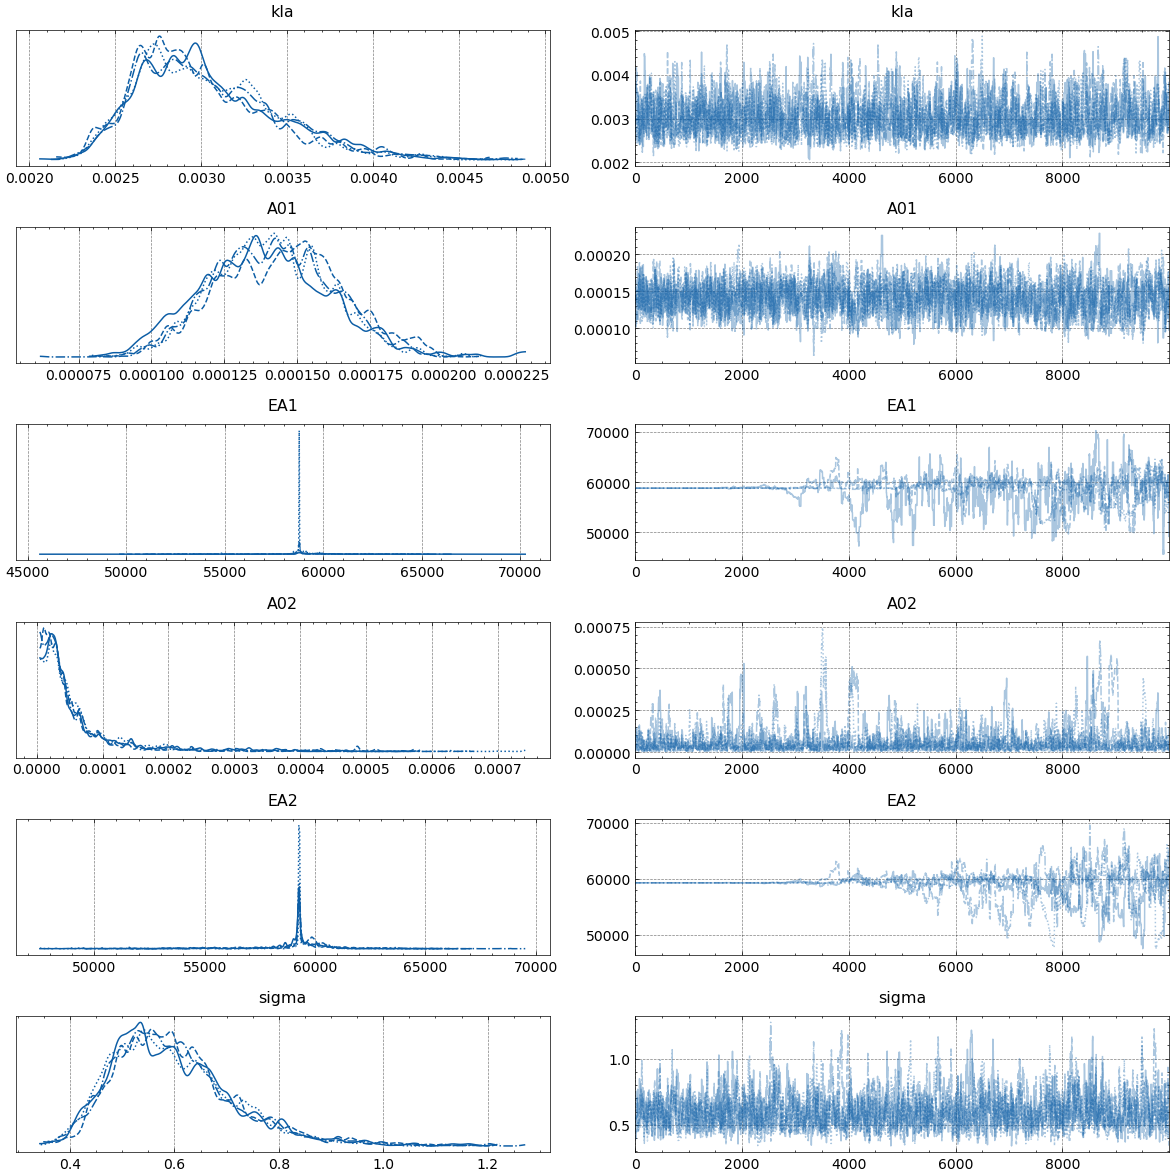

In [27]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

Text(0.5, 0.98, 'Posterior model @ 280 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


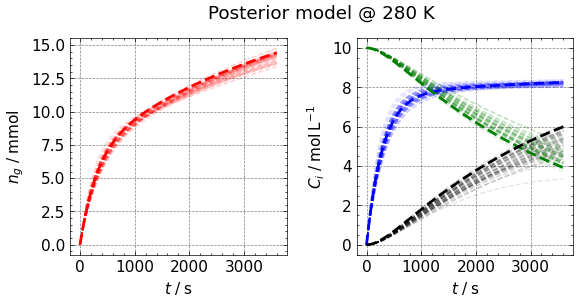

In [28]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 280),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[1, :, :])
plt.suptitle("Posterior model @ 280 K")

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


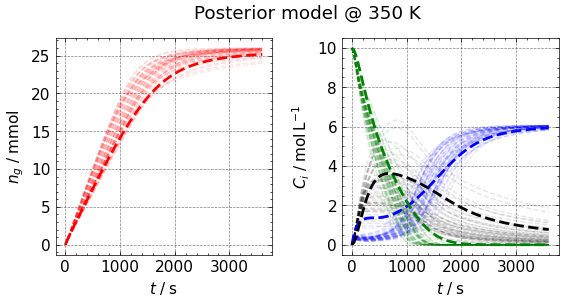

In [29]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

### How does the posterior behave under extrapolation now after adding more data?

In [30]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


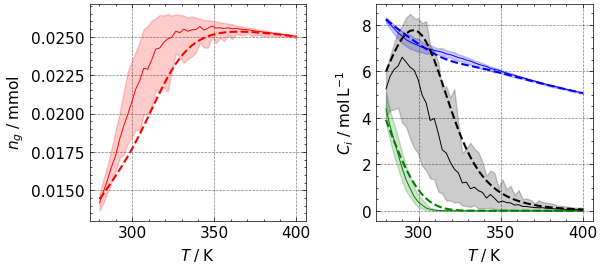

In [31]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

In [32]:
kld280 = KLD(280, model, posterior_idata, n_hyp_samples=1, n_param_samples=1000)
kld330 = KLD(330, model, posterior_idata, n_hyp_samples=1, n_param_samples=1000)
kld380 = KLD(380, model, posterior_idata, n_hyp_samples=1, n_param_samples=1000)

{'kla': array([0.00281272, 0.00278527, 0.00359208, 0.00262275, 0.00320997,
       0.00268725, 0.00306968, 0.00291582, 0.00298321, 0.00303977,
       0.00255954, 0.00320744, 0.00324116, 0.00298541, 0.00307999,
       0.00289664, 0.00286053, 0.00322944, 0.0032201 , 0.00301009,
       0.00268579, 0.00371801, 0.00333124, 0.00261606, 0.00303677,
       0.00303928, 0.00282313, 0.00286755, 0.00324697, 0.002449  ,
       0.0027485 , 0.00316239, 0.00296495, 0.00263914, 0.00264986,
       0.0028565 , 0.00327063, 0.00276129, 0.00367027, 0.00284879,
       0.0030098 , 0.00305517, 0.00285172, 0.00315413, 0.00298891,
       0.00245091, 0.00400167, 0.00340445, 0.00371898, 0.00320144,
       0.00268738, 0.00294007, 0.00294603, 0.00265427, 0.00307934,
       0.00258062, 0.00388577, 0.00262429, 0.00341122, 0.00327429,
       0.00288529, 0.00296113, 0.00335446, 0.00319693, 0.00241266,
       0.00254094, 0.00275848, 0.00320997, 0.0027724 , 0.00362396,
       0.00298216, 0.00326872, 0.00317628, 0.00267743,

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

{'kla': array([0.00312936, 0.00309183, 0.00275841, 0.00312958, 0.00302459,
       0.00302384, 0.0026885 , 0.00269421, 0.00284267, 0.00256766,
       0.00312509, 0.00276652, 0.00274212, 0.00284088, 0.00260334,
       0.00259593, 0.00284062, 0.00287501, 0.0025713 , 0.00286148,
       0.00265381, 0.00280302, 0.00287994, 0.00279323, 0.00286148,
       0.00278207, 0.00272386, 0.00259678, 0.00295675, 0.00269219,
       0.00263852, 0.00314669, 0.00291298, 0.00332166, 0.00266975,
       0.00262947, 0.00267848, 0.00298791, 0.00314285, 0.00266756,
       0.0029172 , 0.0032963 , 0.00256578, 0.00312536, 0.00277469,
       0.00251838, 0.00305892, 0.00272449, 0.00265613, 0.00302808,
       0.00263852, 0.00266975, 0.00299656, 0.0029172 , 0.00275333,
       0.00294631, 0.00280843, 0.0028995 , 0.00250146, 0.00280012,
       0.00304258, 0.00305892, 0.00239288, 0.0028961 , 0.00302474,
       0.00262039, 0.00264849, 0.00274628, 0.00308619, 0.00293649,
       0.00262048, 0.00293608, 0.00277205, 0.00272433,

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

{'kla': array([0.0034511 , 0.00296923, 0.0034511 , 0.00298321, 0.00330208,
       0.00331928, 0.00300893, 0.00332036, 0.0033482 , 0.00299314,
       0.00327699, 0.00329059, 0.00331826, 0.00330988, 0.00298098,
       0.00326414, 0.00310156, 0.00300134, 0.0030005 , 0.00307706,
       0.00304782, 0.0031929 , 0.00293166, 0.00324239, 0.00337923,
       0.00311025, 0.00316166, 0.00333908, 0.00323618, 0.0031518 ,
       0.00313824, 0.00326483, 0.00295915, 0.00299072, 0.00308065,
       0.00331826, 0.00293025, 0.00311771, 0.00313371, 0.00318966,
       0.00298068, 0.00305807, 0.00308434, 0.00312874, 0.00295187,
       0.00314426, 0.00321203, 0.00306474, 0.00317647, 0.00304203,
       0.0030844 , 0.00322208, 0.00323739, 0.00296875, 0.00327105,
       0.00321624, 0.00311834, 0.00296781, 0.0029394 , 0.00294708,
       0.00302299, 0.00297228, 0.00303576, 0.00316166, 0.00351591,
       0.00290636, 0.00315297, 0.00288083, 0.00339186, 0.00336015,
       0.00315199, 0.00293166, 0.00332855, 0.00332855,

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

{'kla': array([0.00259064, 0.00260205, 0.00256085, 0.00255599, 0.00259071,
       0.00268095, 0.00263399, 0.00256503, 0.00259023, 0.00255367,
       0.00262197, 0.00262197, 0.00260022, 0.0025261 , 0.00259613,
       0.00269613, 0.00263869, 0.00263703, 0.00257533, 0.00262764,
       0.0025853 , 0.00256251, 0.00257313, 0.00263938, 0.00263381,
       0.00261491, 0.00261979, 0.00263102, 0.00260853, 0.00264629,
       0.00266218, 0.00268476, 0.00254317, 0.00251046, 0.0025445 ,
       0.00260655, 0.00259297, 0.00258288, 0.00255418, 0.00264973,
       0.00260517, 0.00261269, 0.00250807, 0.00260684, 0.00255046,
       0.00263794, 0.00262653, 0.00261459, 0.00253246, 0.00251021,
       0.00262662, 0.00259254, 0.00259011, 0.00266333, 0.00261863,
       0.00260777, 0.00252964, 0.00260991, 0.00256904, 0.00251128,
       0.00258028, 0.00257296, 0.00262735, 0.00268027, 0.00258568,
       0.00263402, 0.00262329, 0.00256503, 0.00251702, 0.00262894,
       0.00260955, 0.0025608 , 0.00266896, 0.00258028,

In [33]:
print(f"KLD @ 280 K: {kld280:.4f}")
print(f"KLD @ 330 K: {kld330:.4f}")
print(f"KLD @ 380 K: {kld380:.4f}")

KLD @ 280 K: 8.9469
KLD @ 330 K: 13.1070
KLD @ 380 K: 10.1968


the biggest uncertainty is at 320 K, so we can sample there.

## sample the posterior given the third profile at 320 K

In [28]:
## define the second temperature to investigate
y_obs = np.random.normal(y_true[3, :, :], sigma)[::10, :]  # downsample and add noise
model = bmodel(t_obs, 320, y_obs, prior=posterior_idata)
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_006_posterior_inf3.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_006_posterior_inf3.nc")

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform to None will not have any effect in future.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pymc\model\core.py:1393: UserWarning: To disable default transform, please use default_transform=None instead of transform=None. Setting transform t

Loaded posterior from file.


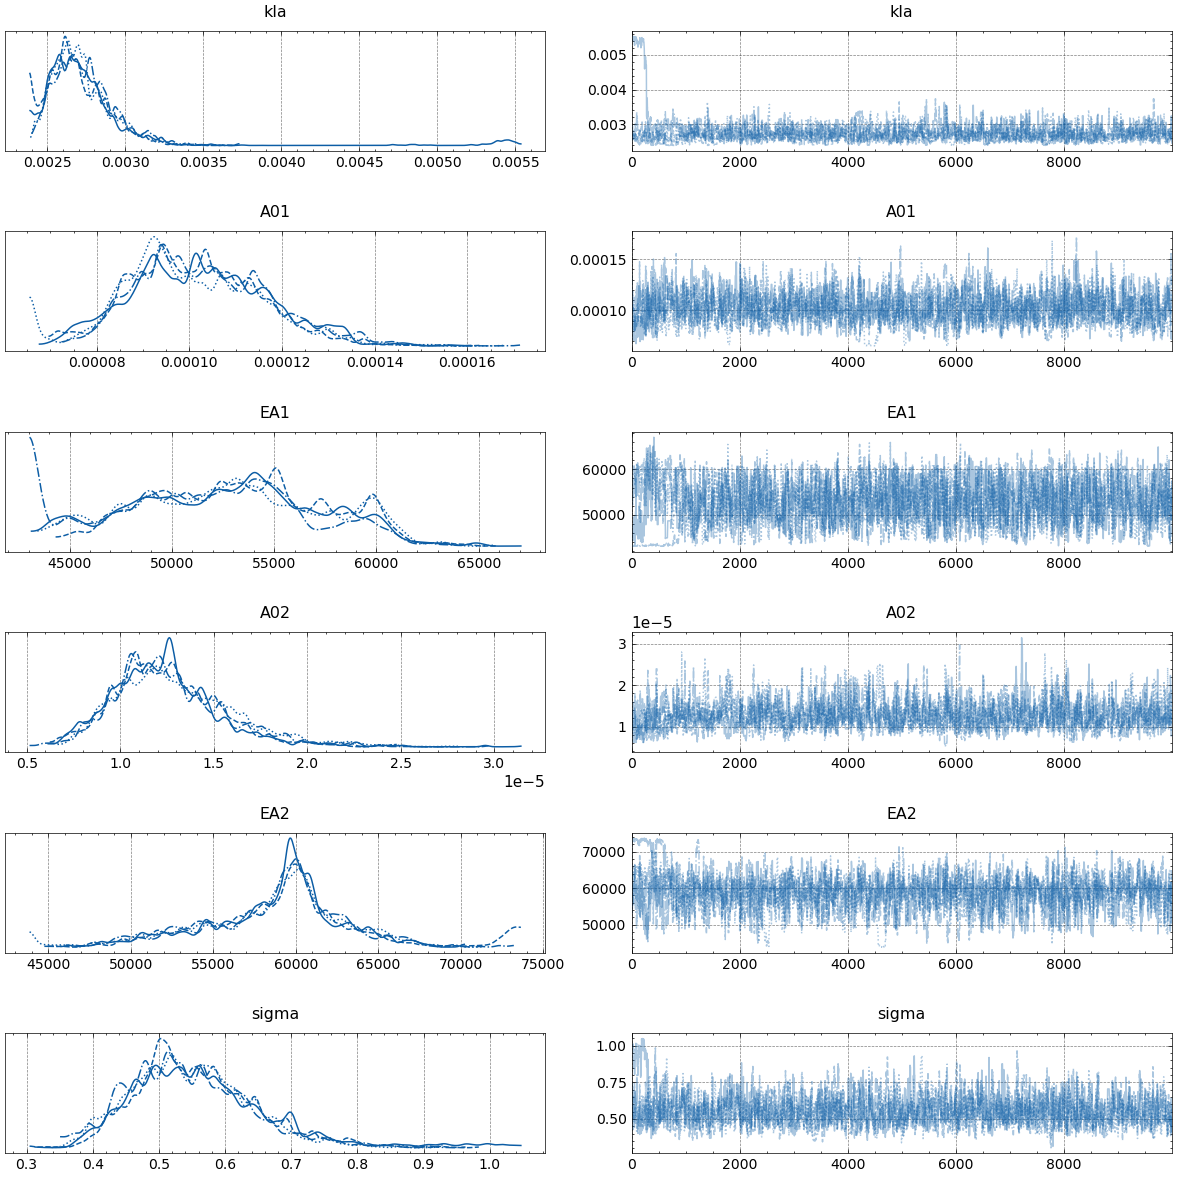

In [29]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A01",
        "EA1",
        "A02",
        "EA2",
        "sigma",
    ],
)
plt.show()

In [30]:
Ts = np.linspace(280, 400, 50)
y_hatses = []
y_trues = []
for T in Ts:
    y_hats = model_inference(
        posterior_idata,
        y0_true,
        times,
        theta_indep=(10e5, T),
        n_samples=99,
    )
    # print(y_hats.shape)
    y_hatses.append(y_hats)
    y_trues.append(
        odeint(
            Chem.reaction,
            t=times,
            y0=y0_true,
            args=((theta_true[0], T, *theta_true[2:]),),
        )
    )
y_hatses = np.array(y_hatses)
y_trues = np.array(y_trues)

Text(0.5, 0.98, 'Posterior model @ 350 K')

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


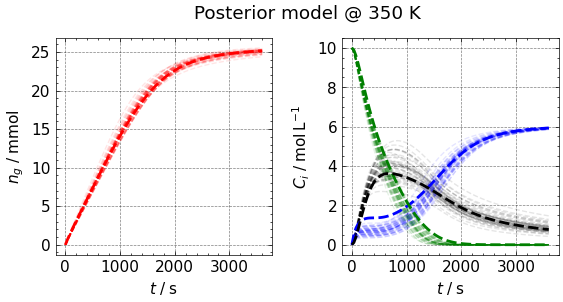

In [31]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$t\;/\;\mathrm{s}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 350),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[4, :, :])
plt.suptitle("Posterior model @ 350 K")

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
C:\Users\hanne\AppData\Local\Temp\ipykernel_12936\2078579502.py:27: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("model at $t = 3600 \mathrm{s}$")


Text(0.5, 0.98, 'model at $t = 3600 \\mathrm{s}$')

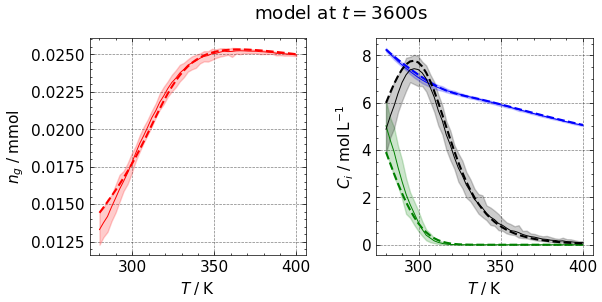

In [32]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -1, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -1, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -1, 0], CI95[:, -1, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -1, 1], CI95[:, -1, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -1, 2], CI95[:, -1, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -1, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -1, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -1, 3], CI95[:, -1, 3], color="black", alpha=0.2)

plt.suptitle("model at $t = 3600 \mathrm{s}$")

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
C:\Users\hanne\AppData\Local\Temp\ipykernel_12936\822489927.py:27: SyntaxWarning: invalid escape sequence '\m'
  plt.suptitle("model at $t = 1800 \mathrm{s}$")


Text(0.5, 0.98, 'model at $t = 1800 \\mathrm{s}$')

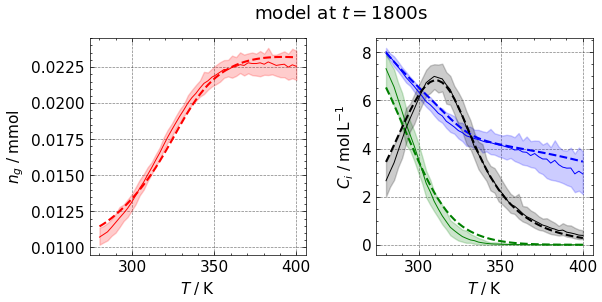

In [33]:
mean_y_hat = y_hatses.mean(axis=1)
CI5 = np.percentile(y_hatses, 5, axis=1)
CI95 = np.percentile(y_hatses, 95, axis=1)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(1, 2),
    h_sep=0.7,
    xlabel=r"$T\;/\;\mathrm{K}$",
    ylabel=[[r"$n_g\;/\;\mathrm{mmol}$", r"$C_i\;/\;\mathrm{mol\,L^{-1}}$"]],
)
axs[0, 0].plot(Ts, mean_y_hat[:, -50, 0], color="red", lw=0.7)
axs[0, 0].plot(Ts, y_trues[:, -50, 0], "--", color="red")
axs[0, 0].fill_between(Ts, CI5[:, -50, 0], CI95[:, -50, 0], color="red", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 1], color="blue", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 1], "--", color="blue")
axs[0, 1].fill_between(Ts, CI5[:, -50, 1], CI95[:, -50, 1], color="blue", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 2], color="green", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 2], "--", color="green")
axs[0, 1].fill_between(Ts, CI5[:, -50, 2], CI95[:, -50, 2], color="green", alpha=0.2)
axs[0, 1].plot(Ts, mean_y_hat[:, -50, 3], color="black", lw=0.7)
axs[0, 1].plot(Ts, y_trues[:, -50, 3], "--", color="black")
axs[0, 1].fill_between(Ts, CI5[:, -50, 3], CI95[:, -50, 3], color="black", alpha=0.2)

plt.suptitle("model at $t = 1800 \mathrm{s}$")